# WheelNet QA: what the model sees on the test set, and what it predicts

A walk through held-out **test** drafts (the last 15% of MSH drafts by time, never used for training or
model selection):

1. The test set at a glance, and the model's overall scores on it
2. One draft through the model's eyes: every input it gets, pick by pick
3. Predictions for a few packs of that draft, against what actually came back
4. Sanity checks: calibration, "does it predict the right number of cards wheeling?", per-pick accuracy
5. Where it is most wrong, and which cards it thinks wheel
6. What the time input does: the same pack scored on different days of the format

Uses `models/wheelnet_time.pt` when it exists (trained with the days-into-format input), otherwise
`models/wheelnet.pt`. Change `DRAFT` / `PACKS` in section 2 to look at other drafts. Runs on CPU in a few
minutes; needs about 10GB of free memory to load MSH.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.patches import Patch

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import COLORS, N_PACKS, N_SEATS, load_tensors
from openlane.evaluate import metrics
from openlane.features import wheel_tensors
from openlane.nn import DraftDataset, WheelNet, collate, draft_context
import pickle

SET, EVENT = "MSH", "PremierDraft"
OUT = ROOT / "results" / f"{SET}.{EVENT}"
MODEL = "wheelnet_time" if (OUT / "models" / "wheelnet_time.pt").exists() else "wheelnet"

# same categorical palette as wheelnet.ipynb, fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(50); pl.Config.set_fmt_str_lengths(200); pl.Config.set_tbl_width_chars(250)

t = load_tensors(SET, EVENT)
passed, back = wheel_tensors(t)
splits = pickle.load(open(ROOT / "data" / "features" / f"{SET}.{EVENT}" / "meta.pkl", "rb"))["splits"]
ckpt = torch.load(OUT / "models" / f"{MODEL}.pt", map_location="cpu", weights_only=False)
model = WheelNet(len(t.names), card_feats=ckpt["card_feats"], **ckpt["cfg"]).eval()
model.load_state_dict(ckpt["state"])
inputs = ckpt.get("inputs")  # None for models trained before per-draft context existed
ctx_all = draft_context(t, **inputs) if inputs and ckpt["cfg"].get("n_ctx") else None

ts = np.array(t.draft_time, dtype="datetime64[s]")
days = (ts - ts.min()).astype(np.float64) / 86400   # what the time input is built from
n, W = t.n_picks, t.n_picks - N_SEATS                # picks per pack, wheel-eligible picks per pack
RANKS = ["unknown", "bronze", "silver", "gold", "platinum", "diamond", "mythic"]
print(f"model: {MODEL}  extra inputs: {inputs or 'none'}")

model: wheelnet_time  extra inputs: {'rank': False, 'skill': False, 'time': True}


## 1. The test set at a glance

The model is scored on a random sample of test drafts (all of them would take longer on CPU and give the
same picture). A card "wheels" if it is still in the pack when that pack comes back to you, 8 picks later.
Only picks 1-6 of each pack can wheel in a 14-card pack, so those are the only picks scored.

In [2]:
test = splits["test"]
rng = np.random.default_rng(0)
sample = np.sort(rng.choice(test, 2000, replace=False))
ds = DraftDataset(t, passed, back, sample, ctx_all)

def predict(ds, batch=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(ds), batch):
            *x, label, mask, ctx = collate([ds[j] for j in range(i, min(i + batch, len(ds)))])
            out.append(torch.sigmoid(model(*x, mask, ctx)).numpy())
    return np.concatenate(out)

prob = predict(ds)
m = metrics(ds.label[ds.mask], prob[ds.mask])
tr = splits["train"]
summary = {
    "train drafts": len(tr), "test drafts": len(test), "scored here": len(sample),
    "train period": f"{t.draft_time[tr[0]][:10]} .. {t.draft_time[tr[-1]][:10]}  (days {days[tr[0]]:.0f}-{days[tr[-1]]:.0f})",
    "test period": f"{t.draft_time[test[0]][:10]} .. {t.draft_time[test[-1]][:10]}  (days {days[test[0]]:.0f}-{days[test[-1]]:.0f})",
    "passed cards scored": int(ds.mask.sum()),
    "share that wheeled": f"{ds.label[ds.mask].mean():.1%}",
    **{k: round(float(v), 4) for k, v in m.items()},
}
pl.DataFrame({"": list(summary), "value": [str(v) for v in summary.values()]})

,value
str,str
"""train drafts""","""48026"""
"""test drafts""","""10292"""
"""scored here""","""2000"""
"""train period""","""2026-06-23 .. 2026-07-10 (days 0-17)"""
"""test period""","""2026-07-16 .. 2026-07-24 (days 23-31)"""
"""passed cards scored""","""377983"""
"""share that wheeled""","""33.3%"""
"""logloss""","""0.4224"""
"""brier""","""0.1382"""


## 2. One draft through the model's eyes

Pick any test draft. The table is **everything the model has seen by the time it scores the chosen pick**,
one row per pick (the model reads this as one history token per row):

* **pack shown**: every card in the pack at that pick (inside the model this row's pack is a
  count-weighted average of card embeddings; the pack being *scored* is not averaged, see section 3)
* **took**: the card the drafter picked (kept as an individual card)
* **others took**: from pick 9 on, the pack you see is one you passed 8 picks earlier coming back, so the
  model also gets the cards the other 7 drafters took out of it. At those picks the **pack shown is
  exactly the cards that wheeled**.

Rank is shown for context; the model only gets the inputs listed above the table.

In [3]:
DRAFT = 0                                # index into the test sample
PACKS = [(0, 1), (0, 5), (1, 2), (2, 0)]  # (pack, pick), 0-based: P1p2, P1p6, P2p3, P3p1

d = sample[DRAFT]
def card_list(idx, cnt):
    return ", ".join(t.names[c] + (f" x{k}" if k > 1 else "") for c, k in zip(idx, cnt) if k > 0)

def history(i, k_end, p_end):
    rows = []
    for k in range(N_PACKS):
        for p in range(n):
            if (k, p) > (k_end, p_end):
                return pl.DataFrame(rows)
            s = k * n + p
            rows.append({
                "pick": f"P{k+1}p{p+1}", "cards": int(ds.pack_n[i, s].sum()),
                "took": t.names[ds.pick[i, s]],
                "others took": card_list(ds.oth[i, s], ds.oth_n[i, s]) if p >= N_SEATS else "",
                "pack shown": card_list(ds.pack[i, s], ds.pack_n[i, s]),
            })
    return pl.DataFrame(rows)

print(f"test draft {d}: drafted {t.draft_time[d]}, day {days[d]:.1f} of the format, rank {RANKS[int(t.rank[d]) + 1]}")
if ctx_all is not None:
    print(f"per-draft input vector the model gets: {np.round(ctx_all[d], 3).tolist()}  ({inputs})")
k_last, p_last = PACKS[-1]
history(DRAFT, k_last, p_last)

test draft 58318: drafted 2026-07-16 22:27:53, day 23.3 of the format, rank silver
per-draft input vector the model gets: [0.7760000228881836, 0.9290000200271606]  ({'rank': False, 'skill': False, 'time': True})


pick,cards,took,others took,pack shown
str,i64,str,str,str
"""P1p1""",14,"""Vision Quest""","""""","""Agent 13, Sharon Carter, Agent of Atlas, Armor Wars, Call Damage Control, Final Act, Futurist Forge, HYDRA Assault Robot, K'un-Lun Warrior, Killmonger, Scourge of Wakanda, Ninja of the Hand, Plains, P…"
"""P1p2""",13,"""We Say Thee Nay!""","""""","""Beast, Erudite Aerialist, Hex Magic, Island, Jessica Jones, Private Eye, Kingpin's Enforcers, Mockingbird, Ace Agent, Pet Avengers, S.H.I.E.L.D. Spy Kit, Super Suit, Titania, Rugged Rumbler, Volcanic …"
"""P1p3""",12,"""Super Intelligence""","""""","""Atlantis Attacks, Crossbones, Malicious Mercenary, HYDRA Troopers, Hawkeye, Young Avenger, Hour of Defeat, Kree Sentinel, Mountain, Murdock's Crusade, Super Intelligence, Surveillance Room, Undercover…"
"""P1p4""",11,"""Stark Industries""","""""","""Atlantean Cavalry, Bold Biochemist, Brave Brawler, Castle Doom, Crimson Operative, Decoy Ploy, Hercules, Prince of Power, Knight of Wundagore, Savage Land Dinosaur, Stark Industries, Ultron Drone"""
"""P1p5""",10,"""Atlantis Attacks""","""""","""Atlantis Attacks, Giant Growth, HULK SMASH!, Madame Hydra, Panther Pounce, Red Room Recruit, Subterranean Cavern, Super Suit, Thirst for Knowledge, Villainous Hideout"""
"""P1p6""",9,"""Gleaming Bastion""","""""","""A.I.M. Synthoids, Brave Brawler, Gleaming Bastion, Hawkeye's Bow, Helicarrier Strike, I Am Iron Man, Pet Avengers, Stolen Stark Tech, Swamp"""
"""P1p7""",8,"""Volcanic Villain""","""""","""Call Damage Control, Giant Growth, HULK SMASH!, Ninja of the Hand, Pym Technologies, Swordsman, Sharp Scoundrel, Visions of Villainy, Volcanic Villain"""
"""P1p8""",7,"""Moonstone, Harsh Mistress""","""""","""A.I.M. Synthoids, Hire a Crew, Kree Sentinel, Moonstone, Harsh Mistress, Ninja of the Hand, Plains, Thunderbolts Conspiracy"""
"""P1p9""",6,"""Armor Wars""","""Agent 13, Sharon Carter, Final Act, Futurist Forge, HYDRA Assault Robot, Killmonger, Scourge of Wakanda, Pym Particles, Wonder Man, Hollywood Hero""","""Agent of Atlas, Armor Wars, Call Damage Control, K'un-Lun Warrior, Ninja of the Hand, Plains"""


## 3. Predictions for a few packs

For each chosen pick: the cards the drafter **passed** (the pack minus their pick), each scored by the model
with P(it comes back 8 picks later). Every passed card is its own token here, so the model scores each card
knowing exactly which other cards are next to it. Blue bars came back, gray bars were taken by the table.

The subtitle compares the number of cards the model expects back (sum of probabilities) with how many
actually came back. The returning pack size is fixed (6 - pick cards in a 14-card pack), and the model is
never told that, so a match is a good sign it has learned the table's behaviour rather than per-card rates.

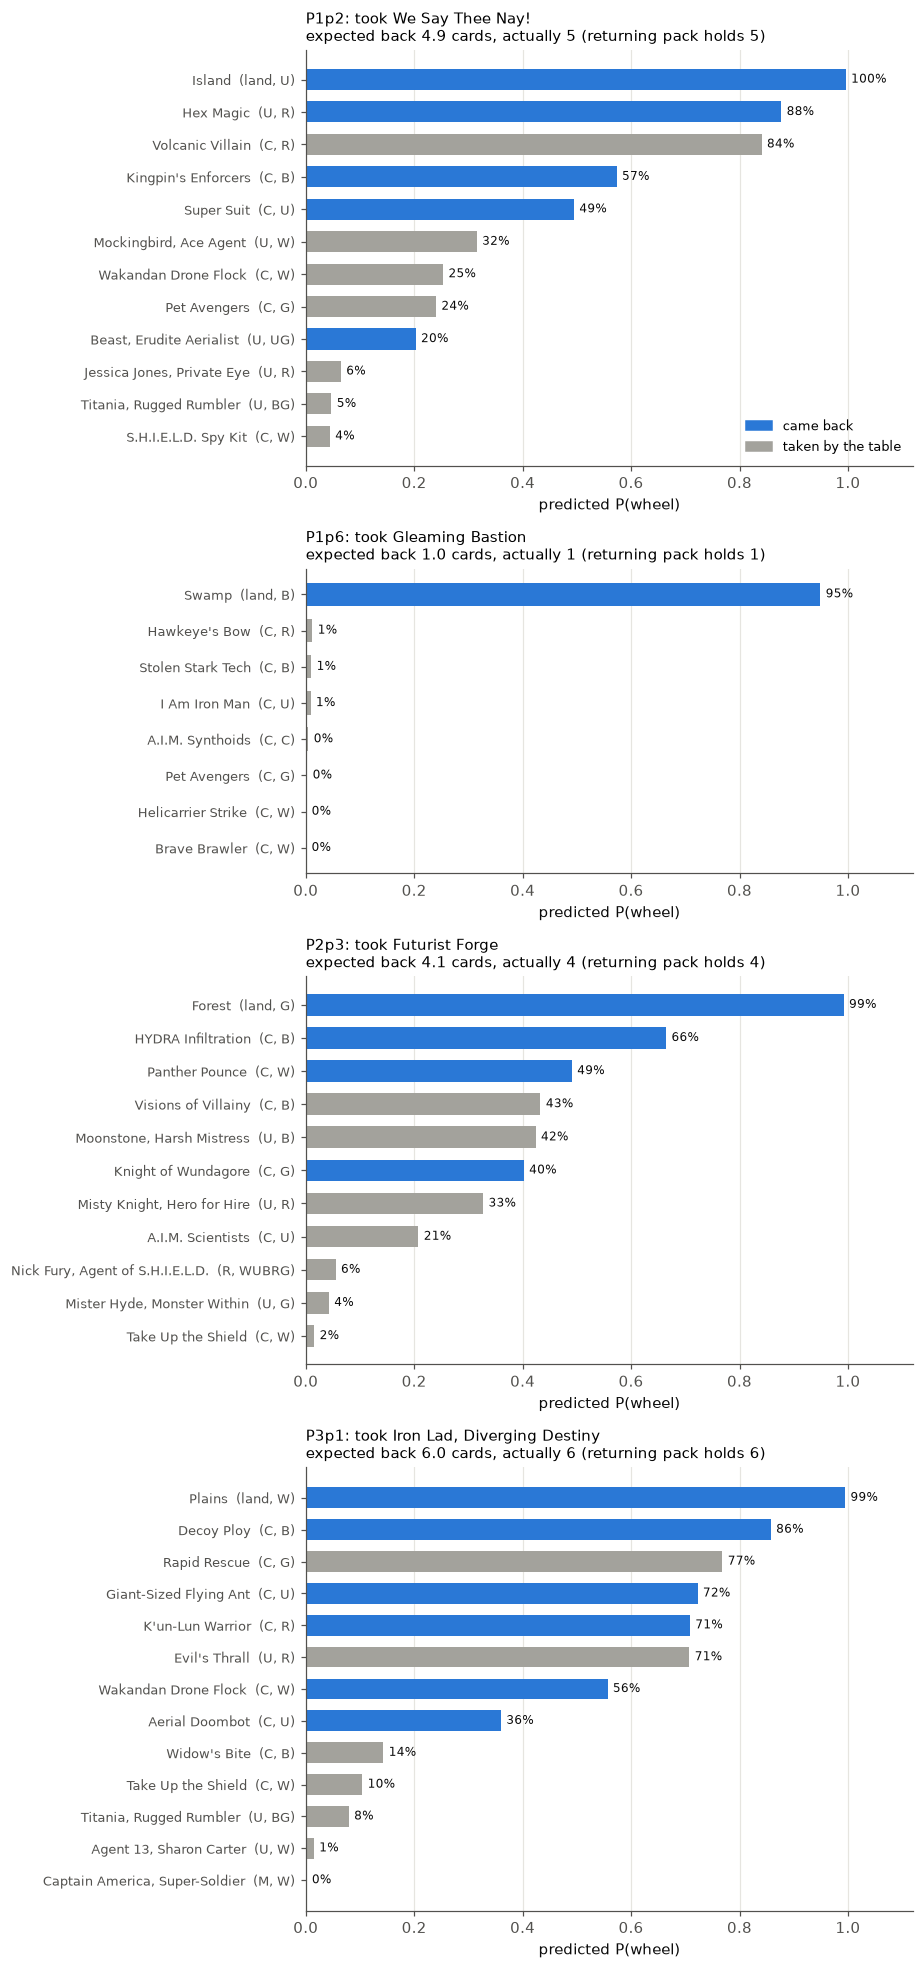

In [4]:
def label(c):
    r = {"common": "C", "uncommon": "U", "rare": "R", "mythic": "M", "basic": "land"}.get(t.meta["rarity"][int(c)], "S")
    col = "".join(x for x in COLORS if t.meta[x][int(c)]) or "C"
    return f"{t.names[c]}  ({r}, {col})"

def show_pack(i, k, p, ax):
    msk = ds.mask[i, k, p]
    idx, pr, lab, cp = ds.idx[i, k, p][msk], prob[i, k, p][msk], ds.label[i, k, p][msk], ds.copies[i, k, p][msk]
    o = np.argsort(pr)
    ax.barh(range(len(o)), pr[o], color=[BLUE if lab[j] else GRAY for j in o], height=0.65)
    ax.set_yticks(range(len(o)), [label(idx[j]) + (f" x{cp[j]}" if cp[j] > 1 else "") for j in o], fontsize=8.5)
    for y, j in enumerate(o):
        ax.text(pr[j] + 0.01, y, f"{pr[j]:.0%}", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, 1.12); ax.grid(axis="y", visible=False); ax.set_xlabel("predicted P(wheel)")
    took = t.names[t.pick[sample[i], k, p]]
    ax.set_title(f"P{k+1}p{p+1}: took {took}\nexpected back {pr.sum():.1f} cards, actually {lab.sum()} "
                 f"(returning pack holds {int(back[sample[i], k, p].sum())})", loc="left", fontsize=9.5)

fig, axes = plt.subplots(len(PACKS), 1, figsize=(8.5, sum(0.3 * ds.mask[DRAFT, k, p].sum() + 1.2 for k, p in PACKS)),
                         gridspec_kw={"height_ratios": [ds.mask[DRAFT, k, p].sum() + 3 for k, p in PACKS]})
for ax, (k, p) in zip(np.atleast_1d(axes), PACKS):
    show_pack(DRAFT, k, p, ax)
axes[0].legend(handles=[Patch(color=BLUE, label="came back"), Patch(color=GRAY, label="taken by the table")],
               loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

Same packs as a table, with what came back at pick +8 (the pack shown at that later pick).

In [5]:
rows = []
for k, p in PACKS:
    msk = ds.mask[DRAFT, k, p]
    for c, pr, lab in zip(ds.idx[DRAFT, k, p][msk], prob[DRAFT, k, p][msk], ds.label[DRAFT, k, p][msk]):
        rows.append({"pick": f"P{k+1}p{p+1}", "card": t.names[c], "P(wheel)": round(float(pr), 3),
                     "came back": bool(lab), "returned at": f"P{k+1}p{p+9}"})
pl.DataFrame(rows).sort(["pick", "P(wheel)"], descending=[False, True])

pick,card,P(wheel),came back,returned at
str,str,f64,bool,str
"""P1p2""","""Island""",0.996,true,"""P1p10"""
"""P1p2""","""Hex Magic""",0.877,true,"""P1p10"""
"""P1p2""","""Volcanic Villain""",0.841,false,"""P1p10"""
"""P1p2""","""Kingpin's Enforcers""",0.573,true,"""P1p10"""
"""P1p2""","""Super Suit""",0.495,true,"""P1p10"""
"""P1p2""","""Mockingbird, Ace Agent""",0.315,false,"""P1p10"""
"""P1p2""","""Wakandan Drone Flock""",0.253,false,"""P1p10"""
"""P1p2""","""Pet Avengers""",0.24,false,"""P1p10"""
"""P1p2""","""Beast, Erudite Aerialist""",0.203,true,"""P1p10"""


## 4. Sanity checks on the whole test sample

* **Calibration**: of the cards given ~30%, do ~30% come back? Points on the diagonal mean the
  probabilities can be read at face value.
* **Cards expected back per pack**: average sum of probabilities vs the true number of distinct cards that
  came back, by pick.
* **Per-pick log loss** against a simple baseline: each card's wheel rate at that pick in the training
  drafts (what an ALSA-style lookup knows).

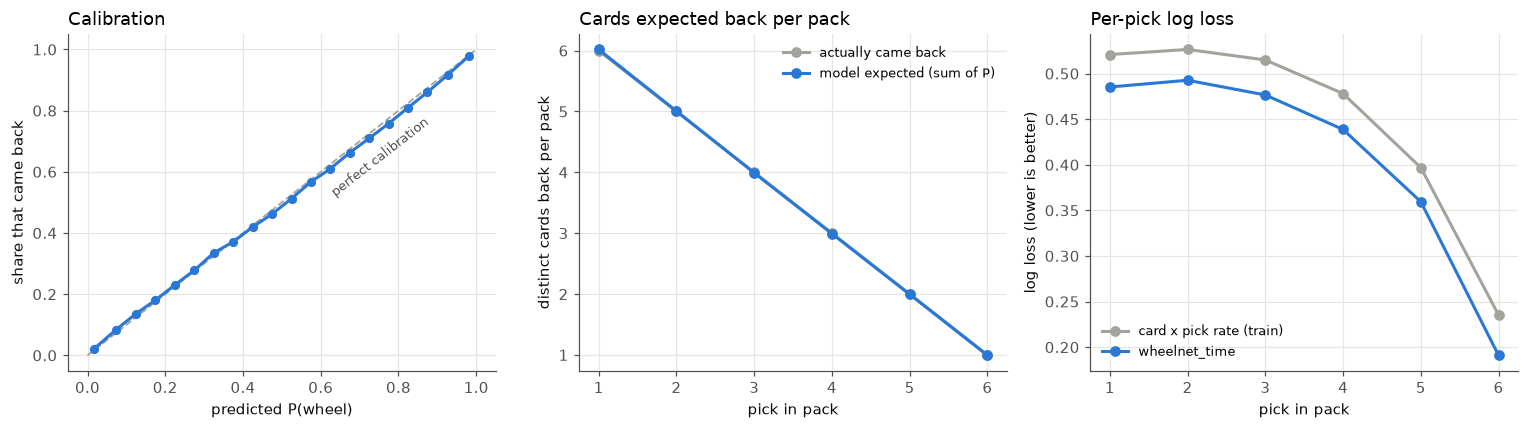

pick,expected,actual,model,baseline
i64,f64,f64,f64,f64
1,6.019,5.9998,0.4853,0.5209
2,5.0062,5.0,0.4927,0.5265
3,3.9914,3.9998,0.4765,0.515
4,2.9929,3.0,0.4387,0.478
5,1.9962,2.0,0.3594,0.3969
6,0.9933,1.0,0.191,0.2352


In [6]:
y, q = ds.label[ds.mask], prob[ds.mask]
bins = np.linspace(0, 1, 21)
b = np.clip(np.digitize(q, bins) - 1, 0, 19)
cal = pl.DataFrame({"b": b, "q": q, "y": y}).group_by("b").agg(pl.col("q").mean(), pl.col("y").mean(), pl.len()).sort("b")

# per card x pick wheel rate in the training drafts
trs = slice(tr[0], tr[-1] + 1)
seen = (passed[trs] > 0).sum((0, 1)).T.astype(np.float64)
came = (back[trs] > 0).sum((0, 1)).T.astype(np.float64)
rate = (came + 20 * came.sum(0) / seen.sum(0)) / (seen + 20)
base = rate[ds.idx.clip(max=len(t.names) - 1), np.arange(W)[None, None, :, None]]

def ll(y, q):
    q = np.clip(q, 1e-6, 1 - 1e-6)
    return float(-(y * np.log(q) + (1 - y) * np.log(1 - q)).mean())

per_pick = []
for p in range(W):
    mk = ds.mask[:, :, p]
    per_pick.append({"pick": p + 1, "expected": (prob[:, :, p] * ds.mask[:, :, p]).sum(-1).mean(),
                     "actual": ds.label[:, :, p].sum(-1).mean(),
                     "model": ll(ds.label[:, :, p][mk], prob[:, :, p][mk]),
                     "baseline": ll(ds.label[:, :, p][mk], base[:, :, p][mk])})
pp = pl.DataFrame(per_pick)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4))
a1.plot([0, 1], [0, 1], color=GRAY, lw=1.2, ls="--")
a1.plot(cal["q"], cal["y"], color=BLUE, marker="o", ms=5)
a1.set_xlabel("predicted P(wheel)"); a1.set_ylabel("share that came back"); a1.set_title("Calibration", loc="left")
a1.text(0.62, 0.52, "perfect calibration", color=MUTED, fontsize=8.5, rotation=38)

x = pp["pick"].to_numpy()
a2.plot(x, pp["actual"], color=GRAY, marker="o", ms=6, label="actually came back")
a2.plot(x, pp["expected"], color=BLUE, marker="o", ms=6, label="model expected (sum of P)")
a2.set_xlabel("pick in pack"); a2.set_ylabel("distinct cards back per pack")
a2.set_title("Cards expected back per pack", loc="left"); a2.legend(fontsize=8.5)

a3.plot(x, pp["baseline"], color=GRAY, marker="o", ms=6, label="card x pick rate (train)")
a3.plot(x, pp["model"], color=BLUE, marker="o", ms=6, label=MODEL)
a3.set_xlabel("pick in pack"); a3.set_ylabel("log loss (lower is better)")
a3.set_title("Per-pick log loss", loc="left"); a3.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
pp.with_columns(pl.col(pl.Float64).round(4))

## 5. Where it is most wrong, and which cards it thinks wheel

Confident misses: cards the model was sure would come back that the table took, and cards it was sure would
be taken that came back. A handful of these is expected at these volumes (a 95% call is wrong 1 time in 20).
Basic lands are left out of the tables in this section: they wheel ~97% of the time, so the top "misses"
would all be someone taking a basic.

In [7]:
i, k, p, j = np.nonzero(ds.mask)
flat = pl.DataFrame({
    "draft": sample[i], "pick": [f"P{a+1}p{b+1}" for a, b in zip(k, p)],
    "card": [t.names[c] for c in ds.idx[i, k, p, j]], "P(wheel)": prob[i, k, p, j],
    "came back": ds.label[i, k, p, j], "baseline": base[i, k, p, j],
    "basic": t.meta["rarity"].to_numpy()[ds.idx[i, k, p, j]] == "basic",
})
nb = flat.filter(~pl.col("basic")).drop("basic")
print("Sure it would come back, but it was taken:")
display(nb.filter(~pl.col("came back")).sort("P(wheel)", descending=True).head(8))
print("Sure it would be taken, but it came back:")
display(nb.filter(pl.col("came back")).sort("P(wheel)").head(8))

Sure it would come back, but it was taken:


draft,pick,card,P(wheel),came back,baseline
i64,str,str,f32,bool,f64
66182,"""P2p1""","""Hire a Crew""",0.977433,false,0.8875
61146,"""P1p1""","""Hire a Crew""",0.974293,false,0.8875
67934,"""P1p1""","""Super Speed""",0.97123,false,0.882259
63777,"""P3p1""","""Super Strength""",0.969998,false,0.873201
58725,"""P2p1""","""Hire a Crew""",0.967974,false,0.8875
67333,"""P2p1""","""Super Speed""",0.966223,false,0.882259
67424,"""P1p1""","""Hire a Crew""",0.965926,false,0.8875
59140,"""P1p2""","""Super Speed""",0.965472,false,0.830106


Sure it would be taken, but it came back:


draft,pick,card,P(wheel),came back,baseline
i64,str,str,f32,bool,f64
60414,"""P3p6""","""Viv Vision, Teen Synthezoid""",0.000838,true,0.004962
58578,"""P1p5""","""Take Up the Shield""",0.001218,true,0.051642
59834,"""P1p6""","""Red Hulk""",0.001343,true,0.017281
67054,"""P1p6""","""Wakandan Drone Flock""",0.001587,true,0.054695
61169,"""P1p4""","""Namor the Sub-Mariner""",0.001747,true,0.034336
67785,"""P2p5""","""Brave Brawler""",0.001825,true,0.06135
67663,"""P1p6""","""We Say Thee Nay!""",0.001903,true,0.019488
66313,"""P2p6""","""Red Hulk""",0.001907,true,0.017281


Per card over the test sample (cards passed at least 150 times): the model's average prediction next to the
actual wheel rate. Note the averages mix picks, so they are not comparable across cards; what matters is
how close the two columns are for each card.

In [8]:
cards = (nb.group_by("card")
         .agg(pl.len().alias("times passed"), pl.col("P(wheel)").mean().alias("mean predicted"),
              pl.col("came back").mean().alias("actual rate"))
         .filter(pl.col("times passed") >= 150)
         .with_columns((pl.col("mean predicted") - pl.col("actual rate")).alias("gap"))
         .with_columns(pl.col(pl.Float64).round(3)))
print("Most likely to wheel:"); display(cards.sort("mean predicted", descending=True).head(10))
print("Least likely to wheel:"); display(cards.sort("mean predicted").head(10))
print("Biggest gaps between prediction and reality:"); display(cards.sort(pl.col("gap").abs(), descending=True).head(10))

Most likely to wheel:


card,times passed,mean predicted,actual rate,gap
str,u32,f32,f64,f64
"""Hire a Crew""",3401,0.731603,0.724,0.007
"""Super Speed""",3400,0.703573,0.685,0.019
"""Super Strength""",3285,0.67147,0.671,0.001
"""Volcanic Villain""",3405,0.638795,0.623,0.015
"""Call Damage Control""",3431,0.622,0.621,0.001
"""Vision of Love""",3266,0.615453,0.619,-0.004
"""Hex Magic""",1391,0.593658,0.585,0.008
"""Project Deathlok Soldier""",3398,0.582714,0.573,0.009
"""Blazing Crescendo""",3252,0.568168,0.539,0.029


Least likely to wheel:


card,times passed,mean predicted,actual rate,gap
str,u32,f32,f64,f64
"""Web Up""",807,0.003373,0.001,0.002
"""Super Villain Lockup""",491,0.00528,0.002,0.003
"""Spider-Woman, Secret Agent""",442,0.005982,0.007,-0.001
"""The Sentry, Golden Guardian""",204,0.008643,0.005,0.004
"""Red Guardian, Super-Soldier""",468,0.01046,0.009,0.002
"""Dark Deed""",390,0.010798,0.005,0.006
"""Agent 13, Sharon Carter""",383,0.012186,0.008,0.004
"""Justice, Vance Astrovik""",326,0.01236,0.018,-0.006
"""Hero in Training""",1016,0.012613,0.013,-0.0


Biggest gaps between prediction and reality:


card,times passed,mean predicted,actual rate,gap
str,u32,f32,f64,f64
"""Iron Fist, Living Weapon""",1213,0.439932,0.355,0.085
"""Giant-Sized Flying Ant""",3024,0.227711,0.303,-0.076
"""Speedball, New Warrior""",1179,0.344076,0.276,0.068
"""Hawkeye, Young Avenger""",1054,0.264908,0.198,0.067
"""Gleaming Bastion""",389,0.039189,0.098,-0.058
"""Avengers Hangar""",1591,0.181126,0.236,-0.055
"""Ronin, Shadow Stalker""",1209,0.447671,0.397,0.051
"""Ghost, Spectral Saboteur""",1217,0.274456,0.224,0.051
"""The Thing, Ben Grimm""",1061,0.232881,0.183,0.05


## 6. What the time input does

The same pack from section 3, re-scored as if it had been drafted on a different day of the format
(everything else identical). The five cards whose prediction moves most are shown. The shaded region is
later than any training draft, so there the model is extrapolating. Skipped for models without the time
input.

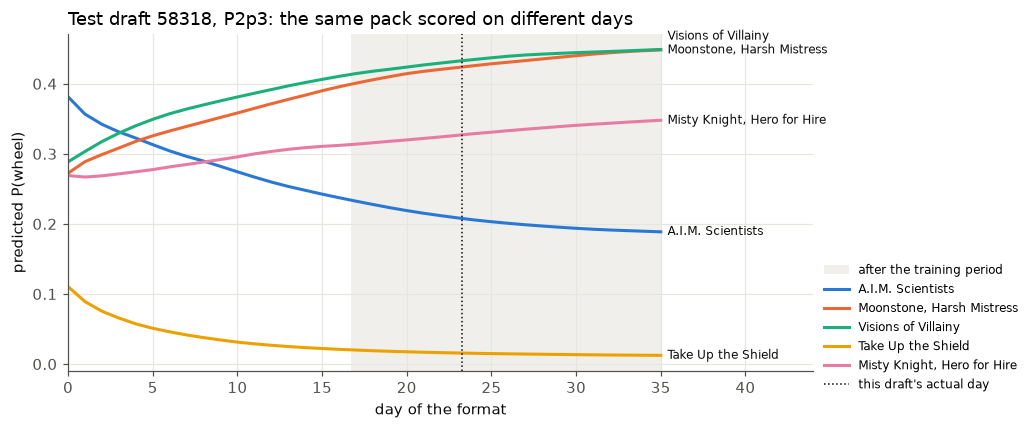

In [9]:
if ctx_all is None or not inputs.get("time"):
    print(f"{MODEL} has no time input")
else:
    k, p = PACKS[2]
    grid = np.arange(0, 36, 1.0)
    x = collate([ds[DRAFT]] * len(grid))
    ctx = x[-1].clone()
    ctx[:, -2] = torch.tensor(grid / 30)                         # same encoding as draft_context
    ctx[:, -1] = torch.tensor(np.log1p(grid) / np.log1p(30))
    with torch.no_grad():
        pr = torch.sigmoid(model(*x[:7], x[8], ctx))[:, k, p].numpy()   # [days, slots]
    msk = ds.mask[DRAFT, k, p]
    idx = ds.idx[DRAFT, k, p][msk]; pr = pr[:, msk]
    top = np.argsort(-(pr.max(0) - pr.min(0)))[:5]
    fig, ax = plt.subplots(figsize=(9.5, 4))
    ax.axvspan(days[tr[-1]], grid[-1], color=GRID, alpha=0.6, lw=0, label="after the training period")
    ys = {c: pr[-1, c] for c in top}  # end-of-line labels, nudged apart so they don't overlap
    gap = 0.045 * (pr[:, top].max() - pr[:, top].min())
    order = sorted(top, key=lambda c: ys[c])
    for a, b in zip(order, order[1:]):
        ys[b] = max(ys[b], ys[a] + gap)
    for c, col in zip(top, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]):
        ax.plot(grid, pr[:, c], color=col, label=t.names[idx[c]])
        ax.text(grid[-1] + 0.4, ys[c], t.names[idx[c]], color=INK, fontsize=8, va="center")
    ax.axvline(days[d], color=INK, lw=1, ls=":", label="this draft's actual day")
    ax.set_xlim(0, grid[-1] + 9); ax.set_xlabel("day of the format"); ax.set_ylabel("predicted P(wheel)")
    ax.set_title(f"Test draft {d}, P{k+1}p{p+1}: the same pack scored on different days", loc="left")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 0.35))
    plt.tight_layout(); plt.show()